<a href="https://colab.research.google.com/github/id1557/deep-learning/blob/main/LoretoDCh_Sprint_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><font color="#113D68" size=5>Redes neuronales y deep learning</font></h1>



<h1><font color="#113D68" size=6>Actividad Semana 2</font></h1>


<br><br>
<div style="text-align: right">
<font size=3>Daniel González</font><br>
<font size=3>Semana 2: Frameworks de Deep Learning: TensorFlow</font><br>
<font size=3>IEBS</font>
</div>

---


In [1]:
import tensorflow as tf
import numpy as np

# Para mostrar gráficas
import matplotlib.pyplot as plt
%matplotlib inline

# Anaconda fixing problem
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

En esta actividad vamos a seguir familiarizándonos con la herramienta *TensorFlow*, para ello vamos a utilizar un dataset donde tendréis que relizar todos los pasos (cargar datos, crear arquitectura de la red, etc.) vosotros mismos para prácticar con la sintásis de *TensorFlow*. Tendéis ejercicios obligatorio y un ejercicio opcional.

# <font color="#004D7F" size=5>Ejercicio</font>
Usando los datos visto en los ejercicios sobre casa y sus precios realiza los ejercicios que se indican.

La información de los datos podéis verla en este enlace:

https://www.tensorflow.org/api_docs/python/tf/keras/datasets/boston_housing/load_data

## <font color="#004D7F" size=4>Ejercicio 1</font>
Carga los datos como hemos visto en el notebook de los ejercicios donde tengas los conjuntos de train y test:

In [2]:
Boston_housing = tf.keras.datasets.boston_housing
(X_train, y_train), (X_test, y_test) = Boston_housing.load_data()

57026/57026 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Explora los tamaños de cada conjunto:

In [9]:
print(f"Dimensiones de entrada del conjunto de entrenamiento (X_train): {X_train.shape}")
print(f"Dimensiones de salida del conjunto de entrenamiento(Y_train): {y_train.shape}")
print(f"Dimensiones de entrada del conjunto de test (X_test): {X_test.shape}")
print(f"Dimensiones de salida del conjunto de test (Y_test): {y_test.shape}")
print(f"Valor de una casa en miles de $ en el conjunto de entrenamiento: {y_train[0]}")
print(f"Valores todas las variables del registro de una casa asociada en X_train: {X_train[0]}")

Dimensiones de entrada del conjunto de entrenamiento (X_train): (404, 13)
Dimensiones de salida del conjunto de entrenamiento(Y_train): (404,)
Dimensiones de entrada del conjunto de test (X_test): (102, 13)
Dimensiones de salida del conjunto de test (Y_test): (102,)
Valor de una casa en miles de $ en el conjunto de entrenamiento: 15.2
Valores todas las variables del registro de una casa asociada en X_train: [  1.23247   0.        8.14      0.        0.538     6.142    91.7
   3.9769    4.      307.       21.      396.9      18.72   ]


Al imprimir los datos por pantalla, podemos observar que el total del conjunto de datos se ha dividido correctamente en el 80% de los datos originales para *X_train* y el 20% para el *X_test*.

Para entender los datos que tenmos, imprimimos un ejemplo de los datos de train:cada conjunto:

## <font color="#004D7F" size=4>Ejercicio 2</font>
Crear una red con la siguiente configuración y entrénala:

- **Configuración de la red**:
    - Arquitectura de la red:
        - *1º Capa*: capa de entrada donde indiques la dimensión de los datos.
        - *2º Capa*: capa densa con 8 neuronas y función de activación *relu*.
        - *3º Capa*: capa densa con 8 neuronas y función de activación *relu*.
        - *4º Capa*: capa de salida con una neurona sin función de activación.
    - Tipo de entrenamiento:
        - *Epochs*: 100
        - *Optimizador*: *adam*
        - *Learning Rate*: 0.001
        - *Función de error*: error cuadrático medio (*mean_squared_error*)

Configuración de la red:

In [10]:
mod_1 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(13, )),
  tf.keras.layers.Dense(8, activation='relu'),
  tf.keras.layers.Dense(8, activation='relu'),
  tf.keras.layers.Dense(1)
  ])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
mod_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

Entrenamiento del modelo:

In [13]:
opt_1 = tf.keras.optimizers.Adam(learning_rate=0.001)
mod_1.compile(optimizer=opt_1, loss='mean_squared_error')

In [14]:
hist = mod_1.fit(X_train, y_train, epochs=100, validation_data=(X_test, y_test))

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 426.6850 - val_loss: 166.1661
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 109.9052 - val_loss: 115.9474
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 101.6572 - val_loss: 94.3843
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 82.9157 - val_loss: 91.7878
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 80.5255 - val_loss: 87.5521
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 77.2544 - val_loss: 84.1225
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 75.9041 - val_loss: 81.8327
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 74.0512 - val_loss: 81.0141
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 72.7654 - val_loss: 78.9785
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 71.0614 - val_loss: 78.1646
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 69.7888 - val_loss: 76.8140
Epoch 12/100
13/13 ━━━━━━━━━━━

Evalúa el modelo usando la función *evaluate* para el conjunto de test:

In [18]:
print(f"Valor del MSE: {mod_1.evaluate(X_test, y_test)}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 44.7526 
Valor del MSE: 44.752586364746094


## <font color="#004D7F" size=4>Ejercicio 3</font>
Crear una red con la siguiente configuración y entrénala:

- **Configuración de la red**:
    - Arquitectura de la red:
        - *1º Capa*: capa de entrada donde indiques la dimensión de los datos.
        - *2º Capa*: capa densa con 16 neuronas y función de activación *relu*.
        - *3º Capa*: capa densa con 16 neuronas y función de activación *relu*.
        - *4º Capa*: capa densa con 32 neuronas y función de activación *relu*.
        - *4º Capa*: capa de salida con una neurona sin función de activación.   
    - Tipo de entrenamiento:
        - *Epochs*: 300
        - *Optimizador*: *adam*
        - *Learning Rate*: 0.0001
        - *Función de error*: error cuadrático medio (*mean_squared_error*)

In [20]:
mod_2 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(13, )),
  tf.keras.layers.Dense(16, activation='relu'),
  tf.keras.layers.Dense(16, activation='relu'),
  tf.keras.layers.Dense(32, activation='relu'),
  tf.keras.layers.Dense(1)
  ])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [21]:
mod_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,073 (4.19 KB)

 Trainable params: 1,073 (4.19 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
opt_2 = tf.keras.optimizers.Adam(learning_rate=0.0001)
mod_2.compile(optimizer=opt_2, loss='mean_squared_error')
hist_2 = mod_2.fit(X_train, y_train, epochs=300, validation_data=(X_test, y_test))

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 2060.6519 - val_loss: 1780.8593
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1463.4255 - val_loss: 1240.2323
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1013.5417 - val_loss: 846.3043
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 694.8611 - val_loss: 579.6942
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 483.3059 - val_loss: 403.3062
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 341.7630 - val_loss: 288.7538
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 249.1697 - val_loss: 216.0627
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 192.7536 - val_loss: 174.2272
Epoch 9/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 162.4193 - val_loss: 153.4115
Epoch 10/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 148.8737 - val_loss: 142.5581
Epoch 11/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 140.6469 - val_loss: 136.3204
Epoch 12

Evalúa el modelo usando la función *evaluate* para el conjunto de test:

In [24]:
print(f"Valor del MSE del modelo 2: {mod_2.evaluate(X_test, y_test)}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 47.3132 
Valor del MSE del modelo 2: 47.31318283081055


## <font color="#004D7F" size=4>Ejercicio 4</font>
Crear una red con la siguiente configuración y entrénala:

- **Configuración de la red**:
    - Arquitectura de la red:
        - *1º Capa*: capa de entrada donde indiques la dimensión de los datos.
        - *2º Capa*: capa densa con 32 neuronas y función de activación *relu*.
        - *3º Capa*: capa densa con 64 neuronas y función de activación *relu*.
        - *4º Capa*: capa densa con 128 neuronas y función de activación *relu*.
        - *4º Capa*: capa de salida con una neurona sin función de activación.   
    - Tipo de entrenamiento:
        - *Epochs*: 2OO
        - *Optimizador*: *adam*
        - *Learning Rate*: 0.001
        - *Función de error*: error cuadrático medio (*mean_squared_error*)

In [26]:
mod_3 = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(13, )),
  tf.keras.layers.Dense(32, activation='relu'),
  tf.keras.layers.Dense(64, activation='relu'),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(1)
  ])

mod_3.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,009 (43.00 KB)

 Trainable params: 11,009 (43.00 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
opt_3 = tf.keras.optimizers.Adam(learning_rate=0.001)
mod_3.compile(optimizer=opt_3, loss='mean_squared_error')
hist_3 = mod_3.fit(X_train, y_train, epochs=200, validation_data=(X_test, y_test))

Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 115.8559 - val_loss: 76.5566
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 66.0493 - val_loss: 63.4446
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 62.0318 - val_loss: 60.9151
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 58.5354 - val_loss: 61.3057
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 63.6841 - val_loss: 64.0588
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 58.4447 - val_loss: 58.0258
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 53.0900 - val_loss: 57.7752
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 55.9962 - val_loss: 66.1818
Epoch 9/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 60.2958 - val_loss: 56.1326
Epoch 10/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 53.1339 - val_loss: 55.3175
Epoch 11/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 51.6841 - val_loss: 56.2022
Epoch 12/200
13/13 ━━━━━━━━━━━━━━━━━━

Evalúa el modelo usando la función *evaluate* para el conjunto de test:

In [28]:
print(f"Valor del MSE del modelo 3: {mod_3.evaluate(X_test, y_test)}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 27.1365 
Valor del MSE del modelo 3: 27.13650131225586


## <font color="#004D7F" size=4>Ejercicio 5</font>
Compara los resultados obtenidos en cada uno de los modelos entrenados y quédate con el mejor. **Justifica tu respuesta**.

El resultado no tiene porqué ser el mismo ya que los entrenamientos son aleatorios, pero un posible resultado podría ser este:

```
- Modelo 1: 83.3437 MSE
- Modelo 2: 51.6446 MSE
- Modelo 3: 27.6275 MSE
```

In [30]:
mse_1 = mod_1.evaluate(X_test, y_test, verbose=0)
mse_2 = mod_2.evaluate(X_test, y_test, verbose=0)
mse_3 = mod_3.evaluate(X_test, y_test, verbose=0)

print("="*50)
print("          COMPARATIVA DE RESULTADOS (MSE)         ")
print("="*50)
print(f"  • Modelo 1: {mse_1:22.4f} MSE")
print(f"  • Modelo 2: {mse_2:22.4f} MSE")
print(f"  • Modelo 3: {mse_3:22.4f} MSE")
print("="*50)

          COMPARATIVA DE RESULTADOS (MSE)         
  • Modelo 1:                44.7526 MSE
  • Modelo 2:                47.3132 MSE
  • Modelo 3:                27.1365 MSE


Además guarda el mejor modelo en formato *.h5* usando la función `save`:

In [31]:
mod_3.save('mod_3.h5')

En este caso, el mejor modelo a guardar es aquel que tiene menor MSE (o error cuadrático medio), ya que compara la diferencia al cuadrado de los valores predichos por el modelo respecto a la realidad.

## <font color="#004D7F" size=4>Ejercicio 6 (Opcional)</font>
Carga el mejor modelo que has guardado en el ejercicio anterior usando la función `load_model` y realizar predicciones usando la función `predict`.

Para realizar las predicciones usa 10 datos cualquier del conjunto de test:

In [35]:
from tensorflow.keras.models import load_model

# 1. Cargamos el modelo guardado
best_model = load_model('mod_3.h5')

# 2. Seleccionamos 10 muestras del conjunto de test
sample_x_test = X_test[:10]
sample_y_test = y_test[:10]

# 3. Realizamos las predicciones
y_hat = best_model.predict(sample_x_test)

# 4. Mostramos los resultados de forma clara
print("="*60)
print("       COMPARATIVA: VALOR REAL VS PREDICCIÓN (K$)")
print("="*60)
for i in range(10):
    print(f" Casa {i+1:02d} | Real: {sample_y_test[i]:5.1f} K$ | Predicción: {y_hat[i][0]:5.1f} K$")
print("="*60)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
       COMPARATIVA: VALOR REAL VS PREDICCIÓN (K$)
 Casa 01 | Real:   7.2 K$ | Predicción:   8.0 K$
 Casa 02 | Real:  18.8 K$ | Predicción:  17.2 K$
 Casa 03 | Real:  19.0 K$ | Predicción:  22.2 K$
 Casa 04 | Real:  27.0 K$ | Predicción:  38.1 K$
 Casa 05 | Real:  22.2 K$ | Predicción:  23.4 K$
 Casa 06 | Real:  24.5 K$ | Predicción:  20.7 K$
 Casa 07 | Real:  31.2 K$ | Predicción:  32.4 K$
 Casa 08 | Real:  22.9 K$ | Predicción:  24.0 K$
 Casa 09 | Real:  20.5 K$ | Predicción:  20.4 K$
 Casa 10 | Real:  23.2 K$ | Predicción:  17.1 K$


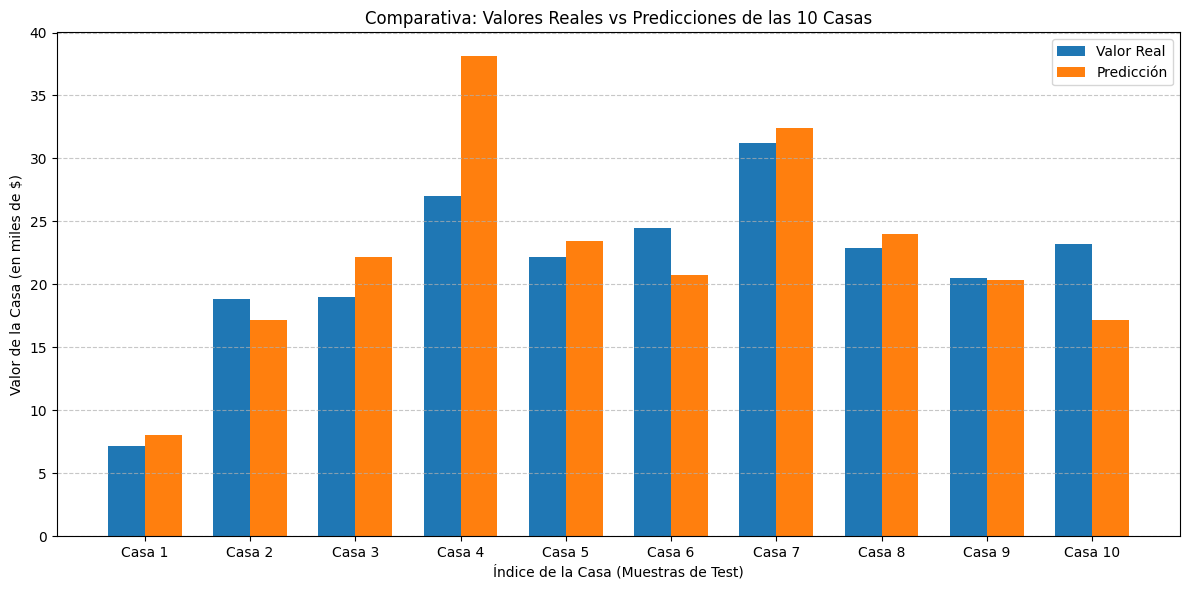

In [37]:
import numpy as np
import matplotlib.pyplot as plt

# Definir el número de casas y la posición de las barras
n_casas = len(sample_y_test)
x = np.arange(n_casas)
ancho_barra = 0.35

# Crear la figura
plt.figure(figsize=(12, 6))

# Dibujar las barras para valores reales y predichos
plt.bar(x - ancho_barra/2, sample_y_test, ancho_barra, label='Valor Real', color='#1f77b4')
plt.bar(x + ancho_barra/2, y_hat.flatten(), ancho_barra, label='Predicción', color='#ff7f0e')

# Personalizar el gráfico
plt.xlabel('Índice de la Casa (Muestras de Test)')
plt.ylabel('Valor de la Casa (en miles de $)')
plt.title('Comparativa: Valores Reales vs Predicciones de las 10 Casas')
plt.xticks(x, [f'Casa {i+1}' for i in range(n_casas)])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mostrar gráfico
plt.tight_layout()
plt.show()